# Enterprise Policy Copilot: Stage 2 - Fixed-Size Chunking

Welcome to Stage 2 of the **Enterprise Policy Copilot** development journey!

In this notebook, we explore and benchmark our first text segmentation strategy: **Fixed-Size Character Chunking with Configurable Overlap**.

---

### 1. What is Chunking?
**Chunking** is the process of breaking down large documents into smaller, semantically manageable segments called *chunks*. Instead of passing an entire 20-page employee handbook into an embedding model or LLM prompt, we divide the text into focused passages.

### 2. Why is Chunking Needed in RAG?
Retrieval-Augmented Generation relies on chunking for three fundamental reasons:
1. **Embedding Model Input Limits**: Transformer-based embedding models (e.g., MiniLM, BGE) have strict token limits (typically 256, 512, or 8192 tokens). Exceeding these limits truncates critical text.
2. **Retrieval Precision**: Finding a specific 2-sentence policy answer (such as *"medical certificates are required after 2 days"*) is far more accurate when searching across small, focused passages than whole documents.
3. **Context Window Optimization**: Feeding concise, highly relevant chunks into the LLM prompt minimizes token costs, reduces latency, and prevents hallucinations.

### 3. What Does Fixed-Size Chunking Do?
**Fixed-size chunking** divides text into windows of a fixed character or token count (e.g., 500 characters) and slides the window forward by a fixed step size. To ensure that thoughts or sentences cut across chunk boundaries are not lost, consecutive chunks share an **overlap** region.


## Section 2: Load Dataset

We load our synthetic policy dataset from `data/sample/synthetic_policies.json` using a **project-relative path**.
We import our reusable chunking functions directly from `src/retrieval/chunking.py`.


In [1]:
# Section 2: Imports and Data Loading
import sys
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Ensure the repository root is in sys.path so we can import from 'src'
current_dir = Path.cwd()
project_root = current_dir if (current_dir / "src").exists() else current_dir.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.retrieval.chunking import fixed_size_chunk, chunk_policy_section, chunk_policy_dataset

# Locate dataset file using relative path
dataset_path = project_root / "data" / "sample" / "synthetic_policies.json"
print(f"Loading synthetic policies from: {dataset_path}")

with open(dataset_path, "r", encoding="utf-8") as f:
    policies_data = json.load(f)

print(f"Successfully loaded {len(policies_data)} policy sections!")


Loading synthetic policies from: C:\Users\sandhiya\OneDrive\Data Science Intern\Enterprise-Policy-Copilot\data\sample\synthetic_policies.json
Successfully loaded 15 policy sections!


## Section 3: Implement Parameters

We configure three core parameters for our baseline fixed-size chunker:

- **`chunk_size` (500 characters)**: The maximum character capacity of each text segment.
- **`chunk_overlap` (100 characters)**: The number of trailing characters from the previous chunk duplicated at the start of the next chunk.
- **`step_size` (400 characters)**: The distance the window advances between consecutive chunks:
  $$\text{step\_size} = \text{chunk\_size} - \text{chunk\_overlap} = 500 - 100 = 400$$

### Why Overlap Matters
Without overlap ($\text{overlap} = 0$), a sentence that splits across two chunks (e.g., *"carry forward up to"* | *"5 days of annual leave"*) loses its semantic coherence in both chunks. Overlap preserves critical boundary context.


In [2]:
# Section 3: Baseline Chunking Parameters
chunk_size = 500
chunk_overlap = 100
step_size = chunk_size - chunk_overlap

print("=== BASELINE CHUNKING PARAMETERS ===")
print(f"  Chunk Size    : {chunk_size} characters")
print(f"  Chunk Overlap : {chunk_overlap} characters")
print(f"  Step Size     : {step_size} characters (chunk_size - chunk_overlap)")
print(f"  Overlap Ratio : {(chunk_overlap / chunk_size) * 100:.1f}%")


=== BASELINE CHUNKING PARAMETERS ===
  Chunk Size    : 500 characters
  Chunk Overlap : 100 characters
  Step Size     : 400 characters (chunk_size - chunk_overlap)
  Overlap Ratio : 20.0%


## Section 4: Apply Fixed-Size Chunking

We apply `chunk_policy_dataset` to process each policy section independently.

**Important Rule**: Different policy sections are **never merged or combined**. Each section is chunked on its own, inheriting the section's full metadata lineage (`doc_id`, `document_title`, `section_heading`, `version`, `effective_date`).


In [3]:
# Section 4: Chunk all policy sections using our modular function
baseline_chunks = chunk_policy_dataset(
    dataset=policies_data,
    chunk_size=chunk_size,
    chunk_overlap=chunk_overlap
)

df_chunks = pd.DataFrame(baseline_chunks)

print(f"Total Policy Sections Ingested : {len(policies_data)}")
print(f"Total Generated Chunks        : {len(baseline_chunks)}")
print(f"Average Chunks per Section    : {len(baseline_chunks) / len(policies_data):.2f}")


Total Policy Sections Ingested : 15
Total Generated Chunks        : 30
Average Chunks per Section    : 2.00


## Section 5: Display Results

Let's inspect the results in detail. We show:
- Original section text and length.
- Generated chunk IDs and their indices.
- Exact start and end character positions.
- Verifying the exact overlap between consecutive chunks.


In [4]:
# Section 5: Detailed Inspection of a Multi-Chunk Section
# Find a section that split into more than 1 chunk (e.g., length > 500 chars)
multi_chunk_section = None
for sec in policies_data:
    if len(sec["section_content"]) > chunk_size:
        multi_chunk_section = sec
        break

if multi_chunk_section:
    print("=" * 80)
    print(f"ORIGINAL SECTION: {multi_chunk_section['document_title']} -> {multi_chunk_section['section_heading']}")
    print(f"Document ID     : {multi_chunk_section['doc_id']}")
    print(f"Total Length    : {len(multi_chunk_section['section_content'])} characters")
    print("=" * 80)
    print(f"Full Text:\n\"{multi_chunk_section['section_content']}\"\n")
    
    # Chunk this section
    sec_chunks = chunk_policy_section(multi_chunk_section, chunk_size=chunk_size, chunk_overlap=chunk_overlap)
    print(f"--- Generated {len(sec_chunks)} Chunks for this Section ---")
    
    for chk in sec_chunks:
        print(f"\n[Chunk Index {chk['chunk_index']}] ID: {chk['chunk_id']}")
        print(f"  Span: chars {chk['start_char']} to {chk['end_char']} (Length: {len(chk['chunk_text'])} chars)")
        print(f"  Text: \"{chk['chunk_text']}\"")
        
    # Check overlap if multiple chunks
    if len(sec_chunks) >= 2:
        overlap_tail = sec_chunks[0]['chunk_text'][-chunk_overlap:]
        overlap_head = sec_chunks[1]['chunk_text'][:chunk_overlap]
        print("\n--- Overlap Verification Between Chunk 0 and Chunk 1 ---")
        print(f"Tail of Chunk 0 ({len(overlap_tail)} chars): \"{overlap_tail}\"")
        print(f"Head of Chunk 1 ({len(overlap_head)} chars): \"{overlap_head}\"")
        print(f"Exact Match: {overlap_tail == overlap_head} [OK]")


ORIGINAL SECTION: Annual Leave Policy -> Eligibility
Document ID     : POL-AL-001
Total Length    : 579 characters
Full Text:
"All full-time employees who have completed a minimum of six months of continuous service with the organization are eligible for annual leave. Part-time employees working at least 20 hours per week become eligible after completing 12 months of continuous service. Contract employees and interns are not eligible for annual leave under this policy. Eligibility is determined based on the employee's hire date as recorded in the HR management system. Employees on a Performance Improvement Plan may have their annual leave requests reviewed by their department head before approval."

--- Generated 2 Chunks for this Section ---

[Chunk Index 0] ID: POL-AL-001_eligibility_chk00
  Span: chars 0 to 500 (Length: 500 chars)
  Text: "All full-time employees who have completed a minimum of six months of continuous service with the organization are eligible for annual leave. Par

## Section 6: Experiment with Different Configurations

To understand the sensitivity of text segmentation, we compare three distinct configurations:

1. **Small Chunks**: `chunk_size = 200`, `chunk_overlap = 40` (Step = 160)
2. **Medium Chunks (Baseline)**: `chunk_size = 500`, `chunk_overlap = 100` (Step = 400)
3. **Large Chunks**: `chunk_size = 800`, `chunk_overlap = 150` (Step = 650)

We evaluate chunk counts and character length statistics across all three configurations.


In [5]:
# Section 6: Comparative Benchmarking
configurations = [
    {"name": "Small Chunks", "chunk_size": 200, "chunk_overlap": 40},
    {"name": "Medium Chunks (Baseline)", "chunk_size": 500, "chunk_overlap": 100},
    {"name": "Large Chunks", "chunk_size": 800, "chunk_overlap": 150},
]

comparison_results = []

for cfg in configurations:
    c_size = cfg["chunk_size"]
    c_overlap = cfg["chunk_overlap"]
    
    chunks = chunk_policy_dataset(policies_data, chunk_size=c_size, chunk_overlap=c_overlap)
    lengths = [len(c["chunk_text"]) for c in chunks]
    
    comparison_results.append({
        "Configuration": cfg["name"],
        "Chunk Size (chars)": c_size,
        "Overlap (chars)": c_overlap,
        "Step Size (chars)": c_size - c_overlap,
        "Total Chunks": len(chunks),
        "Avg Chunk Length": round(sum(lengths) / len(lengths), 1) if lengths else 0,
        "Min Chunk Length": min(lengths) if lengths else 0,
        "Max Chunk Length": max(lengths) if lengths else 0,
    })

df_comparison = pd.DataFrame(comparison_results)
print("=== CHUNKING CONFIGURATION COMPARISON TABLE ===")
display(df_comparison)


=== CHUNKING CONFIGURATION COMPARISON TABLE ===


,Configuration,Chunk Size (chars),Overlap (chars),Step Size (chars),Total Chunks,Avg Chunk Length,Min Chunk Length,Max Chunk Length
0,Small Chunks,200,40,160,67,182.4,42,200
1,Medium Chunks (Baseline),500,100,400,30,388.0,179,500
2,Large Chunks,800,150,650,16,643.1,153,800


## Section 7: Visualize Chunk Overlap

We use `matplotlib` to visualize how the sliding window divides a single policy section into overlapping segments.


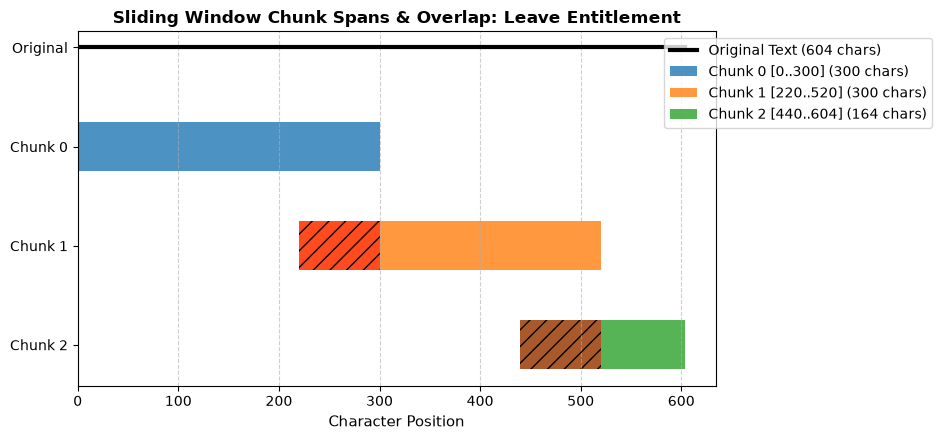

In [6]:
# Section 7: Overlap Visualization with Matplotlib
# Select a representative section that spans multiple chunks
sample_sec = None
for s in policies_data:
    if len(s["section_content"]) >= 600:
        sample_sec = s
        break

if sample_sec is None:
    sample_sec = policies_data[0]

text_len = len(sample_sec["section_content"])
viz_chunks = chunk_policy_section(sample_sec, chunk_size=300, chunk_overlap=80)

fig, ax = plt.subplots(figsize=(10, 3 + len(viz_chunks) * 0.5))

# Plot full text length line
ax.plot([0, text_len], [len(viz_chunks), len(viz_chunks)], color="black", lw=3, label=f"Original Text ({text_len} chars)")

colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

for i, chk in enumerate(viz_chunks):
    start = chk["start_char"]
    end = chk["end_char"]
    y_pos = len(viz_chunks) - 1 - i
    color = colors[i % len(colors)]
    
    # Plot chunk span
    ax.barh(y_pos, width=end-start, left=start, height=0.5, color=color, alpha=0.8,
            label=f"Chunk {i} [{start}..{end}] ({end-start} chars)")
    
    # Highlight overlap with previous chunk if i > 0
    if i > 0:
        prev_end = viz_chunks[i-1]["end_char"]
        overlap_width = prev_end - start
        if overlap_width > 0:
            ax.barh(y_pos, width=overlap_width, left=start, height=0.5,
                    color="red", hatch="//", alpha=0.5)

ax.set_yticks(range(len(viz_chunks) + 1))
ax.set_yticklabels([f"Chunk {len(viz_chunks)-1-j}" for j in range(len(viz_chunks))] + ["Original"])
ax.set_xlabel("Character Position", fontsize=11)
ax.set_title(f"Sliding Window Chunk Spans & Overlap: {sample_sec['section_heading']}", fontsize=12, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.6)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.0))
plt.tight_layout()
plt.show()


## Section 8: Limitations of Fixed-Size Chunking

While fixed-size character chunking is straightforward to implement and computationally efficient, it exhibits several critical limitations in production RAG systems:

1. **Mid-Sentence and Mid-Word Splitting**:
   - Because character chunking slices text at exact character counts (e.g., character index 500), it often splits words or divides sentences in half.
   - Example: *"Employees on extended sick leave will continue to receive standard ben"* | *"efits for up to 90 days."*
   - This corrupts semantic vectors and confuses retrieval ranking.

2. **Blindness to Document Hierarchy & Structural Headings**:
   - Fixed-size chunking treats all text as a flat stream of characters, ignoring semantic units such as headings, numbered lists, and bullet points.

3. **Risk of Context Loss with Very Small Chunks**:
   - Chunks that are too small (e.g., 100–200 characters) lack sufficient context for the embedding model to distinguish between general conditions and policy exceptions.

4. **Information Dilution with Very Large Chunks**:
   - Chunks that are too large (e.g., >1000 characters) encompass multiple unrelated topics in a single passage, diluting cosine similarity scores during vector search.


## Section 9: Summary & Next Steps

### 1. What We Achieved in Stage 2
- Implemented a clean, modular fixed-size chunking function in `src/retrieval/chunking.py`.
- Enforced strict parameter validation and prevented infinite loops.
- Applied chunking across all 15 policy sections without ever cross-contaminating different sections.
- Preserved full document lineage (`doc_id`, `document_title`, `section_heading`, `version`, `effective_date`) on every chunk.
- Benchmarked 3 configurations (200/40, 500/100, 800/150) and visualized overlapping boundaries.
- Validated logic with 13 automated unit tests in `tests/test_chunking.py`.

### 2. Next Chunking Strategies to Explore
In future stages, we will address the limitations of fixed-size chunking by exploring:
- **Sentence-Aware / Recursive Chunking**: Splitting text along natural sentence (`. `, `? `, `! `) and paragraph (`\n\n`) delimiters.
- **Section-Aware Chunking**: Treating natural policy sections as the fundamental semantic unit.
- **Sentence-Window Retrieval**: Embedding individual sentences for precise matching while retrieving the surrounding paragraph window for generation context.
